# Lab 12-04 · High-Frequency Analysis Methods

Companion to [chapter 12-04](../../chapters/12-04-high-frequency-analysis-methods.md). Four parts: open-circuit time constants by test sources checked against the full circuit; short-circuit time constants against the exact low corner; pole splitting as the compensation capacitor grows; and a map of source-follower peaking. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigvals
from scipy.optimize import brentq, minimize_scalar

TP = 2 * math.pi


def matrices(nodes, elems, fixed):
    idx = {n: i for i, n in enumerate(nodes)}
    n = len(nodes); G, Cm = np.zeros((n, n)), np.zeros((n, n)); bG, bC = np.zeros(n), np.zeros(n)
    fx = dict(fixed); fx.setdefault('0', 0.0)
    def add(M, bv, i, j, val):
        if i not in idx: return
        if j in idx: M[idx[i], idx[j]] += val
        else: bv[idx[i]] -= val * fx[j]
    for e in elems:
        if e[0] in ('R', 'C'):
            a, c, val = e[1], e[2], (1 / e[3] if e[0] == 'R' else e[3])
            M, bv = (G, bG) if e[0] == 'R' else (Cm, bC)
            add(M, bv, a, a, val); add(M, bv, a, c, -val); add(M, bv, c, c, val); add(M, bv, c, a, -val)
        elif e[0] == 'G':
            d, s, cp, cn, gm = e[1:]
            add(G, bG, d, cp, gm); add(G, bG, d, cn, -gm); add(G, bG, s, cp, -gm); add(G, bG, s, cn, gm)
        elif e[0] == 'I':
            if e[1] in idx: bG[idx[e[1]]] -= e[3]
            if e[2] in idx: bG[idx[e[2]]] += e[3]
    return G, Cm, bG, bC, idx


def response(nodes, elems, fixed, f):
    G, Cm, bG, bC, idx = matrices(nodes, elems, fixed); s = 1j * TP * f
    x = np.linalg.solve(G + s * Cm, bG + s * bC)
    return {n: x[idx[n]] for n in nodes}


def seen(nodes, resistive, a, b, shorts=()):
    el = list(resistive) + [('R', p, q, 1e-6) for p, q in shorts] + [('I', b, a, 1.0)]
    r = response(nodes, el, {}, 0.0)
    return float(np.real(r.get(a, 0.0) - r.get(b, 0.0)))


gm, Cgs, Cgd, CL, RS, RL = 1e-3, 72.6667e-15, 6e-15, 100e-15, 10e3, 20e3

## Part 1 · Open-circuit time constants, checked against the full circuit

In [2]:
res = [('R', 'g', '0', RS), ('G', 'd', '0', 'g', '0', gm), ('R', 'd', '0', RL)]
caps = [('C_gs', 'g', '0', Cgs), ('C_gd', 'g', 'd', Cgd), ('C_L', 'd', '0', CL)]
taus = {name: seen(['g', 'd'], res, a, b) * c for name, a, b, c in caps}
total = sum(taus.values())
for name, t in taus.items():
    print(f"{name:5s} tau = {t * 1e9:.4f} ns ({100 * t / total:4.1f}%)")
G, Cm, *_ = matrices(['g', 'd'], res + [('C', a, b, c) for _, a, b, c in caps], {})
lam = eigvals(G, -Cm); lam = lam[np.isfinite(lam)]
print(f"sum {total * 1e9:.4f} ns; b1 from the full circuit's poles {np.real(-np.sum(1 / lam)) * 1e9:.4f} ns")

C_gs  tau = 0.7267 ns (17.7%)
C_gd  tau = 1.3800 ns (33.6%)
C_L   tau = 2.0000 ns (48.7%)
sum 4.1067 ns; b1 from the full circuit's poles 4.1067 ns


## Part 2 · Short-circuit time constants against the exact low corner

The discrete amplifier of Example 12-04.3, with its bypass capacitor swept.

In [3]:
base = [('R', 'vs', 'a', 1e3), ('R', 'g', '0', 1e6), ('G', 'd', 'sn', 'g', 'sn', 4e-3), ('R', 'sn', '0', 2e3),
        ('R', 'd', '0', 5e3), ('R', 'o', '0', 10e3)]
nodes = ['a', 'g', 'sn', 'd', 'o']
for CS in (1e-6, 10e-6, 100e-6):
    amp = base + [('C', 'a', 'g', 0.1e-6), ('C', 'sn', '0', CS), ('C', 'd', 'o', 1e-6)]
    H = lambda f: response(nodes, amp, {'vs': 1.0}, f)['o']
    Am = abs(H(1e6)); fL = brentq(lambda f: abs(H(f)) - Am / math.sqrt(2), 0.1, 1e5)
    w = 1 / (1.001e6 * 0.1e-6) + 1 / (222.22 * CS) + 1 / (15e3 * 1e-6)
    print(f"C_S = {CS * 1e6:6.1f} uF: SCTC estimate {w / TP:7.2f} Hz, exact {fL:7.2f} Hz")

C_S =    1.0 uF: SCTC estimate  728.40 Hz, exact  707.46 Hz
C_S =   10.0 uF: SCTC estimate   83.82 Hz, exact   72.32 Hz
C_S =  100.0 uF: SCTC estimate   19.36 Hz, exact   14.03 Hz


## Part 3 · Pole splitting (the chapter's guided exercise)

**Predict first:** as $C_c$ grows from 0 to 1 pF in Example 12-04.4, does the second pole rise steadily and the first fall steadily?

C_c =  0.01 pF: poles   4011.78 kHz and   167.0 MHz
C_c =  0.10 pF: poles    587.52 kHz and   445.0 MHz
C_c =  1.00 pF: poles     61.75 kHz and   596.6 MHz


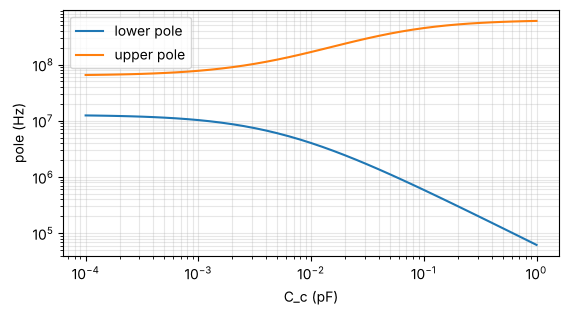

In [4]:
def poles(Cc):
    el = [('R', 'n1', '0', 50e3), ('C', 'n1', '0', 50e-15), ('G', 'n2', '0', 'n1', '0', 4e-3), ('R', 'n2', '0', 12.5e3),
          ('C', 'n2', '0', 1e-12), ('C', 'n1', 'n2', Cc)]
    G, Cm, *_ = matrices(['n1', 'n2'], el, {})
    lam = eigvals(G, -Cm); return np.sort(np.abs(lam[np.isfinite(lam)].real)) / TP


ccs = np.logspace(-16, -12, 41)
P = np.array([poles(c) for c in ccs])
for c in (1e-14, 1e-13, 1e-12):
    p = poles(c); print(f"C_c = {c * 1e12:5.2f} pF: poles {p[0] / 1e3:9.2f} kHz and {p[1] / 1e6:7.1f} MHz")
plt.figure(figsize=(6.4, 3.2))
plt.loglog(ccs * 1e12, P[:, 0], label='lower pole'); plt.loglog(ccs * 1e12, P[:, 1], label='upper pole')
plt.xlabel('C_c (pF)'); plt.ylabel('pole (Hz)'); plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()

**What to notice.** Both poles move monotonically and fastest at small $C_c$: a fraction of a picofarad already separates them by three decades.

## Part 4 · Where a follower peaks

Peak of the follower's response (Example 12-04.5's device) over a grid of source resistance and load capacitance.

In [5]:
def peak_db(RS_, CL_):
    el = [('R', 'vs', 'g', RS_), ('C', 'g', '0', Cgd), ('C', 'g', 'o', Cgs), ('G', '0', 'o', 'g', 'o', gm), ('C', 'o', '0', CL_)]
    r = minimize_scalar(lambda lf: -abs(response(['g', 'o'], el, {'vs': 1.0}, 10 ** lf)['o']), bounds=(6, 11),
                        method='bounded', options={'xatol': 1e-8})
    return 20 * math.log10(max(-r.fun, 1.0))


print("R_S \\ C_L   0.1 pF   1 pF   10 pF")
for RS_ in (1e3, 10e3, 30e3, 100e3):
    print(f"{RS_ / 1e3:6.0f} kOhm " + "  ".join(f"{peak_db(RS_, c):6.2f}" for c in (0.1e-12, 1e-12, 10e-12)) + " dB")

R_S \ C_L   0.1 pF   1 pF   10 pF
     1 kOhm   0.00    0.00    0.00 dB
    10 kOhm   2.81    0.16    0.00 dB
    30 kOhm   3.66    2.59    0.00 dB
   100 kOhm   2.31    4.92    0.35 dB


**What to take away.** Time constants find the bandwidth *and* the culprit; the open-circuit sum is exact as $b_1$ and conservative as a bandwidth; short-circuit time constants size coupling and bypass capacitors; one bridging capacitor splits two poles by orders of magnitude; and a follower from a high-impedance source into a capacitive load peaks.